In [1]:
%pip install -U langgraph langchain-groq

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langgraph]


In [2]:
from langgraph.graph import StateGraph,START,END
from typing import TypedDict,Literal


In [3]:
class QuadState(TypedDict):
  a:int
  b:int
  c:int

  equation: str
  discriminant:float
  result:str

In [4]:
def show_equation(state: QuadState):
  equation = f'{state["a"]}x2{state["b"]}x{state["c"]}'
  return {'equation':equation}


In [5]:
def calculate_discrimanant(state: QuadState):

    discriminant = state["b"]**2 - (4*state["a"]*state["c"])

    return {'discriminant': discriminant}

In [6]:
def calculate_roots(state: QuadState):
    root1 = (-state["b"] + state["discriminant"]**0.5)/(2*state["a"])
    root2 = (-state["b"] - state["discriminant"]**0.5)/(2*state["a"])

    result = f'The roots are {root1} and {root2}'

    return {'result': result}


In [7]:
def repeated_roots(state: QuadState):

    root = (-state["b"])/(2*state["a"])

    result = f'Only repeating root is {root}'

    return {'result': result}

In [8]:
def no_real_roots(state: QuadState):

    result = f'No real roots'

    return {'result': result}

In [9]:
def check_condition(state:QuadState)->Literal["real_roots","repeated_roots","no_real_roots"]:
  if(state["discriminant"]>0):
    return "real_roots"
  elif(state["discriminant"]==0):
    return "repeated_roots"
  else:
    return "no_real_roots"

In [13]:
graph = StateGraph(QuadState)

graph.add_node('show_equation', show_equation)
graph.add_node('calculate_discrimanant', calculate_discrimanant)
graph.add_node('real_roots', calculate_roots)
graph.add_node('repeated_roots', repeated_roots)
graph.add_node('no_real_roots', no_real_roots)

# Edges
graph.add_edge(START, 'show_equation')
graph.add_edge('show_equation', 'calculate_discrimanant')

# Conditional routing
graph.add_conditional_edges(
    'calculate_discrimanant',
    check_condition
)

graph.add_edge('real_roots', END)
graph.add_edge('repeated_roots', END)
graph.add_edge('no_real_roots', END)

workflow = graph.compile()

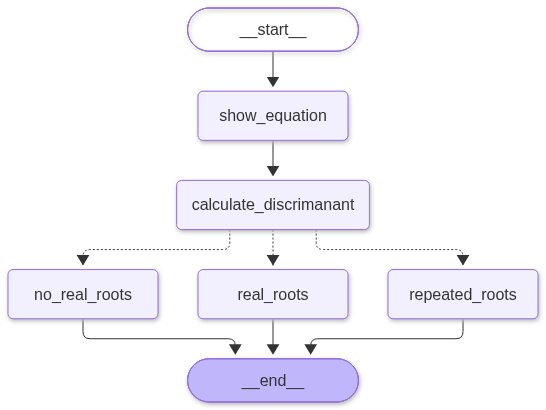

In [14]:
workflow=graph.compile()
workflow